# Lab Task # 05 – Spatial Filtering and Convolution
**Name:** Raja Afzal  
**Roll No:** 2024-SE-25  
**Course:** Digital Image Processing Lab  
**Lab Instructor:** Engr. Fahad Nisar  
**Department:** Software Engineering, The University of Azad Jammu and Kashmir

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data, img_as_ubyte

# Load test images as grayscale uint8 and keep clean originals untouched
camera_clean = img_as_ubyte(data.camera())
coins_clean = img_as_ubyte(data.coins())
chelsea_clean = img_as_ubyte(cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2GRAY))

images_clean = {
    "camera": camera_clean,
    "coins": coins_clean,
    "chelsea": chelsea_clean,
}

for name, img in images_clean.items():
    print(f"{name:8s} -> shape: {img.shape}, dtype: {img.dtype}")

camera   -> shape: (512, 512), dtype: uint8
coins    -> shape: (303, 384), dtype: uint8
chelsea  -> shape: (300, 451), dtype: uint8


## 1. Helper Functions, Kernels (R1–R4), and `conv2d_loop`

In [2]:
def to_uint8_clipped(arr_float64: np.ndarray) -> np.ndarray:
    """R2: Round float64 values, clip to [0, 255], and cast to uint8."""
    arr_f64 = np.asarray(arr_float64, dtype=np.float64)
    return np.clip(np.rint(arr_f64), 0, 255).astype(np.uint8)


def validate_odd_size(ksize: int) -> None:
    """R4: Kernel size must be a positive odd integer (3, 5, or 7)."""
    if not isinstance(ksize, (int, np.integer)) or ksize < 1 or ksize % 2 == 0:
        raise ValueError(f"Kernel size must be a positive odd integer, got {ksize}.")


def make_mean_kernel(ksize: int) -> np.ndarray:
    """R3 & R4: Mean kernel with weights equal to 1 / ksize^2, summing to 1."""
    validate_odd_size(ksize)
    kernel = np.full((ksize, ksize), 1.0 / (ksize * ksize), dtype=np.float64)
    print(f"Mean {ksize}x{ksize} weight sum: {kernel.sum():.12f}")
    assert np.isclose(kernel.sum(), 1.0, atol=1e-12)
    return kernel


def make_gaussian_kernel(ksize: int, sigma: float | None = None) -> np.ndarray:
    """R3 & R4: Discrete 2D Gaussian kernel normalized so weights sum to 1."""
    validate_odd_size(ksize)
    if ksize == 3 and sigma is None:
        g1d = np.array([1.0, 2.0, 1.0], dtype=np.float64)
        g1d /= g1d.sum()
        kernel = np.outer(g1d, g1d)
    else:
        if sigma is None:
            sigma = 0.3 * ((ksize - 1) * 0.5 - 1) + 0.8
        ax = np.arange(-(ksize // 2), ksize // 2 + 1, dtype=np.float64)
        xx, yy = np.meshgrid(ax, ax)
        kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
        kernel /= kernel.sum()

    print(f"Gaussian {ksize}x{ksize} weight sum: {kernel.sum():.12f}")
    assert np.isclose(kernel.sum(), 1.0, atol=1e-12)
    return kernel


def conv2d_loop(img: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """
    True 2D convolution using nested loops:
    - Flips kernel 180 degrees (both axes).
    - Pads image borders with reflect padding (R1).
    - Computes weighted sum in float64 and returns float64 same shape as input (R2).
    """
    img_f64 = np.asarray(img, dtype=np.float64)
    ker_f64 = np.asarray(kernel, dtype=np.float64)

    if img_f64.ndim != 2 or ker_f64.ndim != 2:
        raise ValueError("Both img and kernel must be 2D arrays.")

    kh, kw = ker_f64.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel dimensions must be odd.")

    pad_h, pad_w = kh // 2, kw // 2
    kernel_flipped = ker_f64[::-1, ::-1]
    padded = np.pad(img_f64, pad_width=((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")

    h, w = img_f64.shape
    output = np.zeros((h, w), dtype=np.float64)

    for r in range(h):
        for c in range(w):
            acc = 0.0
            for kr in range(kh):
                for kc in range(kw):
                    acc += padded[r + kr, c + kc] * kernel_flipped[kr, kc]
            output[r, c] = acc

    return output

## 2. Dry-Run Hand Calculations & Verification

### Dry-Run Exercise 1 — Spike Response ($3 \times 3$ Neighbourhood)
Input $3 \times 3$ neighbourhood:
$$\begin{bmatrix} 40 & 40 & 40 \\ 40 & 255 & 40 \\ 40 & 40 & 40 \end{bmatrix}$$

1. **3×3 Mean Filter** (all weights $= \frac{1}{9}$):
   * Sum of all 9 pixels: $40 \times 8 + 255 = 320 + 255 = 575$.
   * Center output: $\frac{575}{9} = 63.888\overline{8} \rightarrow \text{round} \rightarrow \mathbf{64}$ (`uint8`).

2. **3×3 Gaussian Filter** ($\frac{1}{16} \begin{bmatrix} 1 & 2 & 1 \\ 2 & 4 & 2 \\ 1 & 2 & 1 \end{bmatrix}$, weight sum $= 1$):
   * Corner weights ($4$ corners, each $\frac{1}{16}$, pixel $40$): $4 \times (\frac{1}{16} \times 40) = 10.0$.
   * Edge weights ($4$ edges, each $\frac{2}{16}$, pixel $40$): $4 \times (\frac{2}{16} \times 40) = 20.0$.
   * Center weight ($\frac{4}{16}$, pixel $255$): $\frac{4}{16} \times 255 = 63.75$.
   * Total sum: $10.0 + 20.0 + 63.75 = 93.75 \rightarrow \text{round} \rightarrow \mathbf{94}$ (`uint8`).

3. **3×3 Median Filter**:
   * Sorted values: $[40, 40, 40, 40, 40, 40, 40, 40, 255]$.
   * Middle (5th) element: $\mathbf{40}$ (`uint8`).

---

### Dry-Run Exercise 2 — Reflect Padding at Corner $(0, 0)$
Input $3 \times 3$ image:
$$\begin{bmatrix} 10 & 20 & 30 \\ 40 & 50 & 60 \\ 70 & 80 & 90 \end{bmatrix}$$

Padded $3 \times 3$ neighbourhood centered at $(0, 0)$ using `np.pad(..., mode="reflect")`:
$$\begin{bmatrix} 50 & 40 & 40 \\ 20 & 10 & 20 \\ 20 & 40 & 50 \end{bmatrix}$$

* Sum of pixels: $50 + 40 + 40 + 20 + 10 + 20 + 20 + 40 + 50 = 330$.
* Mean value: $\frac{330}{9} = 36.666\overline{6} \rightarrow \text{round} \rightarrow \mathbf{37}$ (`uint8`).

In [3]:
# --- Dry-Run 1 Verification ---
spike_win = np.array(
    [[40, 40, 40], [40, 255, 40], [40, 40, 40]], dtype=np.uint8
)
k_mean_3 = make_mean_kernel(3)
k_gauss_3 = make_gaussian_kernel(3)

dr1_mean = to_uint8_clipped(conv2d_loop(spike_win, k_mean_3))[1, 1]
dr1_gauss = to_uint8_clipped(conv2d_loop(spike_win, k_gauss_3))[1, 1]
dr1_median = cv2.medianBlur(spike_win, 3)[1, 1]
print(
    f"Dry-Run 1 -> Mean: {dr1_mean}, Gaussian: {dr1_gauss}, Median: {dr1_median}"
)

# --- Dry-Run 2 Verification ---
dr2_img = np.array(
    [[10, 20, 30], [40, 50, 60], [70, 80, 90]], dtype=np.uint8
)
dr2_mean_corner = to_uint8_clipped(conv2d_loop(dr2_img, k_mean_3))[0, 0]
print(f"Dry-Run 2 -> Top-left (0,0) mean output: {dr2_mean_corner}")

# --- Verify conv2d_loop vs OpenCV on a real image ---
test_gray = camera_clean
loop_mean_u8 = to_uint8_clipped(conv2d_loop(test_gray, k_mean_3))
cv_blur_u8 = cv2.blur(test_gray, (3, 3), borderType=cv2.BORDER_REFLECT_101)

max_diff = int(np.max(np.abs(loop_mean_u8.astype(np.int16) - cv_blur_u8.astype(np.int16))))
print(
    f"Max pixel difference between conv2d_loop and cv2.blur (3x3) on camera: {max_diff}"
)

Mean 3x3 weight sum: 1.000000000000
Gaussian 3x3 weight sum: 1.000000000000
Dry-Run 1 -> Mean: 64, Gaussian: 94, Median: 40
Dry-Run 2 -> Top-left (0,0) mean output: 37
Max pixel difference between conv2d_loop and cv2.blur (3x3) on camera: 0


## 3. Noise Generation (R5) & Reproducibility Check

In [4]:
def add_gaussian_noise(
    img: np.ndarray, sigma: float = 20.0, seed: int = 5
) -> np.ndarray:
    """R2 & R5: Add zero-mean Gaussian noise using fixed seed."""
    rng = np.random.default_rng(seed)
    noisy_f64 = img.astype(np.float64) + rng.normal(
        loc=0.0, scale=sigma, size=img.shape
    )
    return to_uint8_clipped(noisy_f64)


def add_salt_pepper(
    img: np.ndarray, amount: float = 0.05, seed: int = 5
) -> np.ndarray:
    """R1, R2 & R5: Add salt (255) and pepper (0) noise using fixed seed."""
    rng = np.random.default_rng(seed)
    out = img.copy()
    total_pixels = img.size
    num_salt = int(np.floor(amount * total_pixels * 0.5))
    num_pepper = int(np.floor(amount * total_pixels * 0.5))

    coords = rng.permutation(total_pixels)
    salt_idx = coords[:num_salt]
    pepper_idx = coords[num_salt : num_salt + num_pepper]

    flat = out.ravel()
    flat[salt_idx] = 255
    flat[pepper_idx] = 0
    return out


def generate_noisy_suite(
    img_dict: dict[str, np.ndarray], seed: int = 5
) -> dict[str, dict[str, np.ndarray]]:
    suite = {}
    for name, clean in img_dict.items():
        suite[name] = {
            "clean": clean,
            "gaussian": add_gaussian_noise(clean, sigma=20, seed=seed),
            "salt_pepper": add_salt_pepper(clean, amount=0.05, seed=seed),
        }
    return suite


noisy_suite_run1 = generate_noisy_suite(images_clean, seed=5)
noisy_suite_run2 = generate_noisy_suite(images_clean, seed=5)

for name in images_clean:
    g_same = np.array_equal(
        noisy_suite_run1[name]["gaussian"], noisy_suite_run2[name]["gaussian"]
    )
    sp_same = np.array_equal(
        noisy_suite_run1[name]["salt_pepper"], noisy_suite_run2[name]["salt_pepper"]
    )
    print(f"{name:8s} -> Gaussian identical: {g_same}, S&P identical: {sp_same}")

camera   -> Gaussian identical: True, S&P identical: True
coins    -> Gaussian identical: True, S&P identical: True
chelsea  -> Gaussian identical: True, S&P identical: True


## 4. Filter Wrappers & Rule Compliance Checks (R1–R4)

In [5]:
def apply_mean_filter(img: np.ndarray, ksize: int = 3) -> np.ndarray:
    kernel = make_mean_kernel(ksize)
    out = to_uint8_clipped(conv2d_loop(img, kernel))
    assert out.shape == img.shape and out.dtype == np.uint8
    return out


def apply_gaussian_filter(img: np.ndarray, ksize: int = 3) -> np.ndarray:
    validate_odd_size(ksize)
    _ = make_gaussian_kernel(ksize)
    out = cv2.GaussianBlur(
        img, (ksize, ksize), sigmaX=0, borderType=cv2.BORDER_REFLECT_101
    )
    out = to_uint8_clipped(out)
    assert out.shape == img.shape and out.dtype == np.uint8
    return out


def apply_median_filter(img: np.ndarray, ksize: int = 3) -> np.ndarray:
    validate_odd_size(ksize)
    out = cv2.medianBlur(img, ksize)
    out = to_uint8_clipped(out)
    assert out.shape == img.shape and out.dtype == np.uint8
    return out


# R4 Rule Check: Demonstrate even kernel size rejection
for bad_k in [2, 4, 6]:
    try:
        apply_median_filter(camera_clean, bad_k)
    except ValueError as e:
        print(f"Rejected even kernel size {bad_k}: {e}")

try:
    cv2.medianBlur(camera_clean, 4)
except cv2.error as e:
    print(f"cv2.medianBlur(img, 4) raised error as expected: {e}")

Rejected even kernel size 2: Kernel size must be a positive odd integer, got 2.
Rejected even kernel size 4: Kernel size must be a positive odd integer, got 4.
Rejected even kernel size 6: Kernel size must be a positive odd integer, got 6.
cv2.medianBlur(img, 4) raised error as expected: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\median_blur.dispatch.cpp:192: error: (-215:Assertion failed) (ksize % 2 == 1) && (_src0.dims() <= 2 ) in function 'cv::medianBlur'



## 5. Comparison Grids (Noise Grid, 3×3 Filter Grid, & Kernel Size Grid)

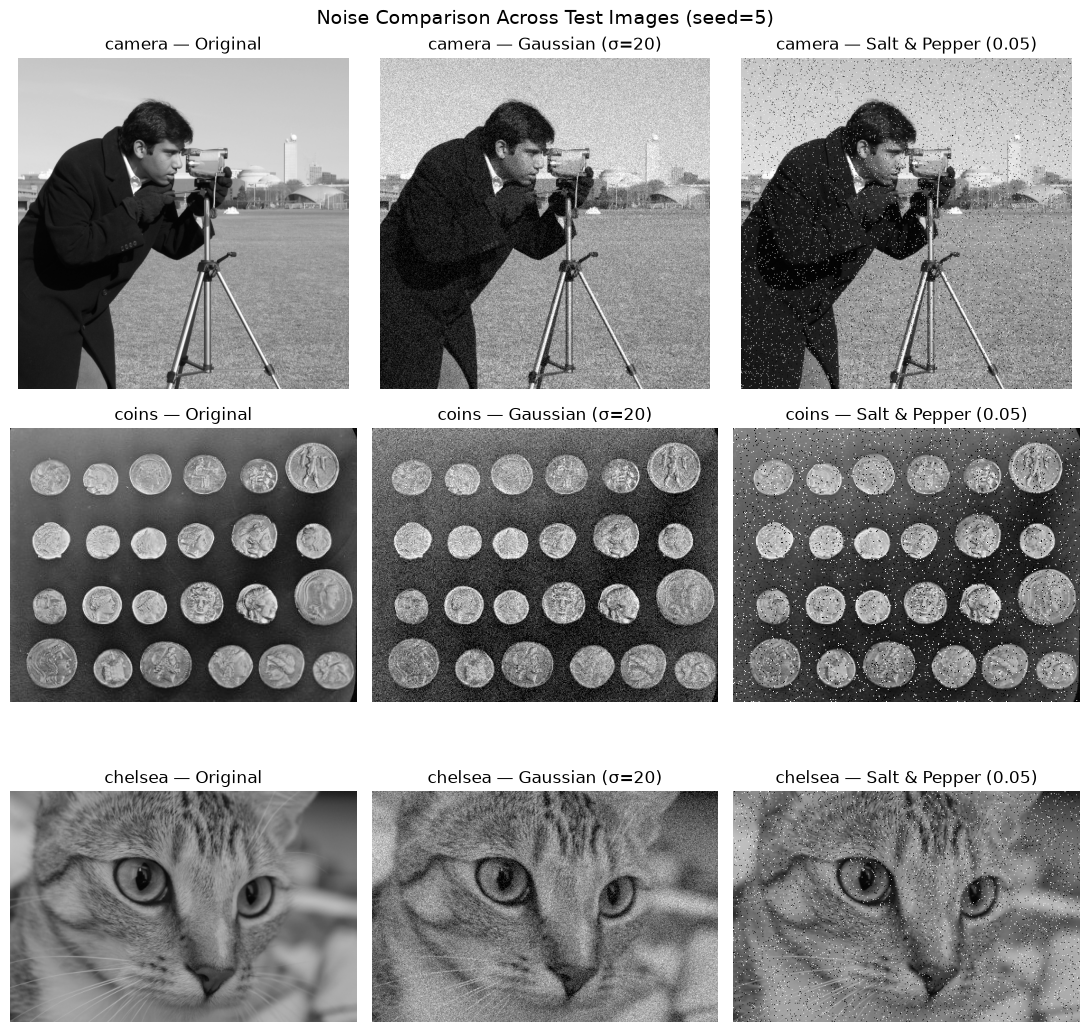

Mean 3x3 weight sum: 1.000000000000
Gaussian 3x3 weight sum: 1.000000000000
Mean 3x3 weight sum: 1.000000000000
Gaussian 3x3 weight sum: 1.000000000000
Mean 3x3 weight sum: 1.000000000000
Gaussian 3x3 weight sum: 1.000000000000
Mean 3x3 weight sum: 1.000000000000
Gaussian 3x3 weight sum: 1.000000000000
Mean 3x3 weight sum: 1.000000000000
Gaussian 3x3 weight sum: 1.000000000000
Mean 3x3 weight sum: 1.000000000000
Gaussian 3x3 weight sum: 1.000000000000


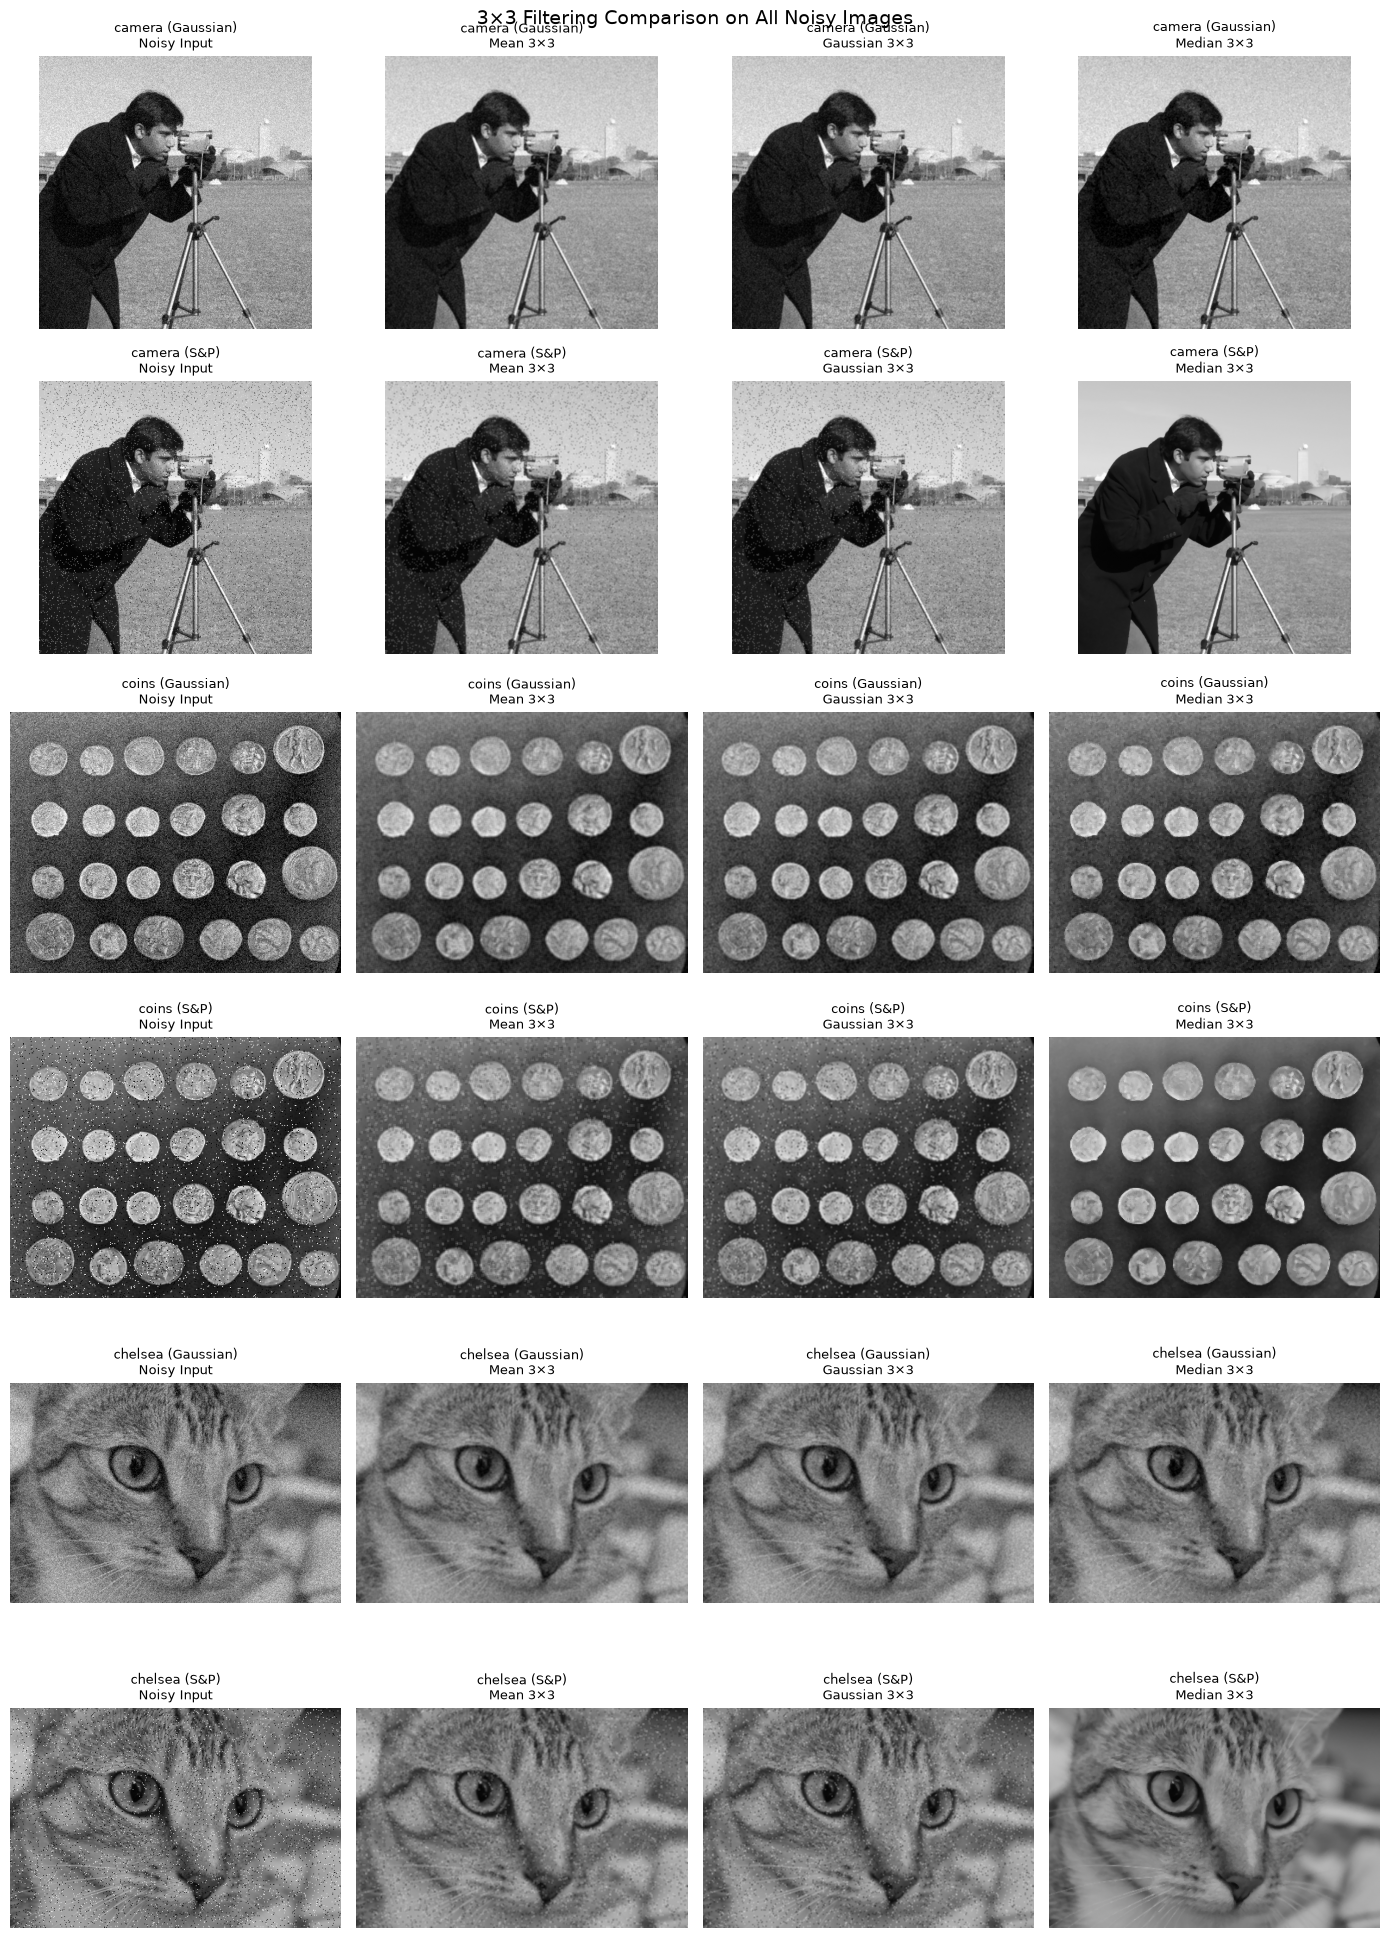

MSE vs clean — camera   [gaussian   ]: 374.09
MSE vs clean — camera   [salt_pepper]: 1096.37
MSE vs clean — coins    [gaussian   ]: 391.66
MSE vs clean — coins    [salt_pepper]: 991.93
MSE vs clean — chelsea  [gaussian   ]: 398.65
MSE vs clean — chelsea  [salt_pepper]: 862.95

Selected noisiest image: camera (salt_pepper) (MSE=1096.37)
Mean 3x3 weight sum: 1.000000000000
Mean 5x5 weight sum: 1.000000000000
Mean 7x7 weight sum: 1.000000000000
Gaussian 3x3 weight sum: 1.000000000000
Gaussian 5x5 weight sum: 1.000000000000
Gaussian 7x7 weight sum: 1.000000000000


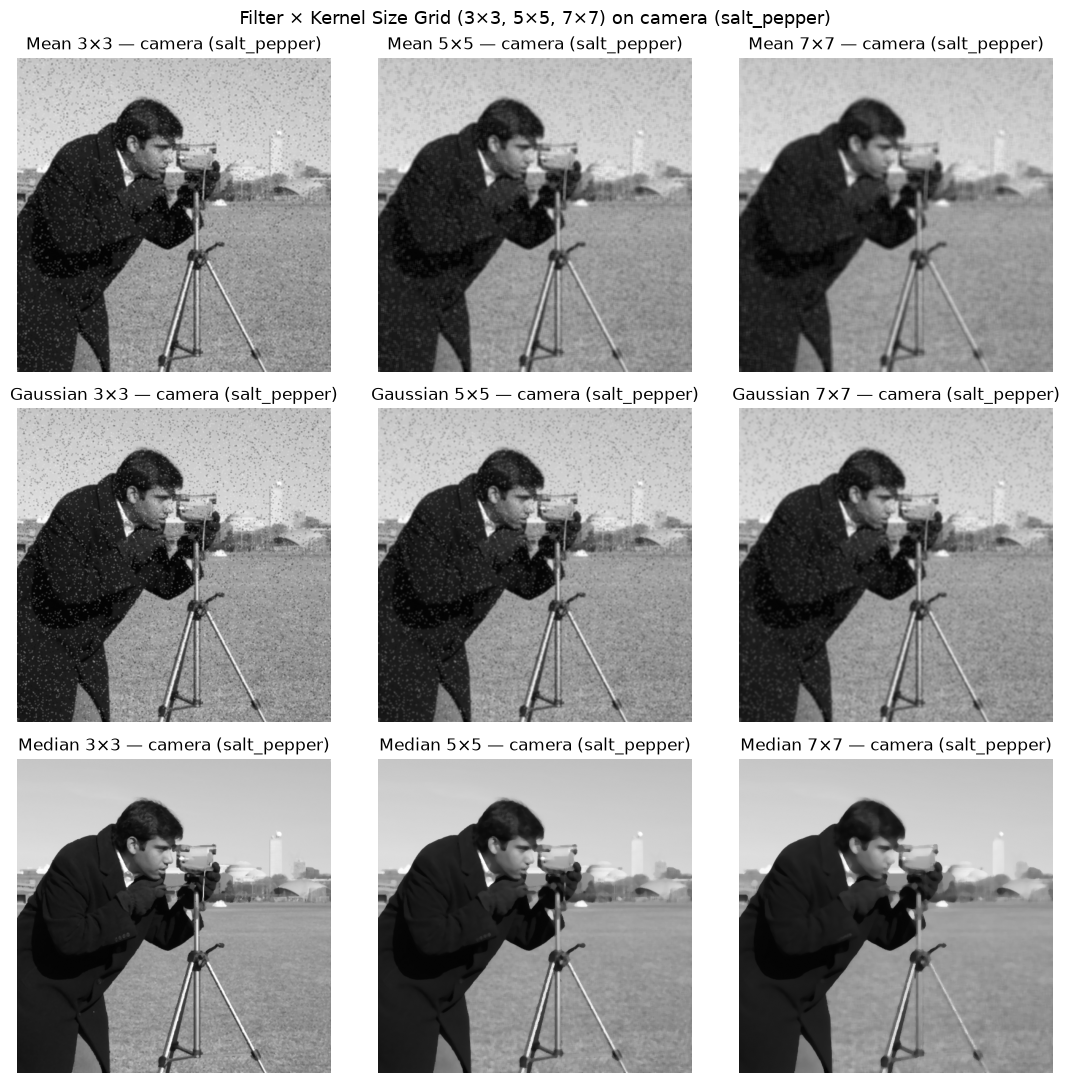

In [6]:
# 1. Noise Comparison Grid (3 test images x [Clean, Gaussian, Salt & Pepper])
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
noise_cols = [
    ("clean", "Original"),
    ("gaussian", "Gaussian (σ=20)"),
    ("salt_pepper", "Salt & Pepper (0.05)"),
]

for row_idx, (img_name, bundle) in enumerate(noisy_suite_run1.items()):
    for col_idx, (key, col_title) in enumerate(noise_cols):
        ax = axes[row_idx, col_idx]
        ax.imshow(bundle[key], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{img_name} — {col_title}")
        ax.axis("off")

plt.suptitle("Noise Comparison Across Test Images (seed=5)", fontsize=14)
plt.tight_layout()
plt.show()

# 2. 3x3 Filter Comparison Grid across every noisy image (6 rows x 4 cols)
filter_3x3_fns = [
    ("Noisy Input", None),
    ("Mean 3×3", lambda im: apply_mean_filter(im, 3)),
    ("Gaussian 3×3", lambda im: apply_gaussian_filter(im, 3)),
    ("Median 3×3", lambda im: apply_median_filter(im, 3)),
]

rows_3x3 = []
for img_name, bundle in noisy_suite_run1.items():
    for n_key, n_label in [("gaussian", "Gaussian"), ("salt_pepper", "S&P")]:
        rows_3x3.append((f"{img_name} ({n_label})", bundle[n_key]))

fig, axes = plt.subplots(len(rows_3x3), len(filter_3x3_fns), figsize=(14, 20))
for r_i, (row_label, noisy_img) in enumerate(rows_3x3):
    for c_i, (f_label, fn) in enumerate(filter_3x3_fns):
        res = noisy_img if fn is None else fn(noisy_img)
        ax = axes[r_i, c_i]
        ax.imshow(res, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{row_label}\n{f_label}", fontsize=9)
        ax.axis("off")

plt.suptitle("3×3 Filtering Comparison on All Noisy Images", fontsize=14)
plt.tight_layout()
plt.show()

# 3. 3x3 Grid (3 filters x 3 kernel sizes: 3x3, 5x5, 7x7) on the noisiest image
best_mse = -1.0
noisiest_label = ""
noisiest_img = None

for img_name, bundle in noisy_suite_run1.items():
    clean = bundle["clean"].astype(np.float64)
    for n_key in ["gaussian", "salt_pepper"]:
        mse = float(np.mean((clean - bundle[n_key].astype(np.float64)) ** 2))
        print(f"MSE vs clean — {img_name:8s} [{n_key:11s}]: {mse:.2f}")
        if mse > best_mse:
            best_mse = mse
            noisiest_label = f"{img_name} ({n_key})"
            noisiest_img = bundle[n_key]

print(f"\nSelected noisiest image: {noisiest_label} (MSE={best_mse:.2f})")

ksizes = [3, 5, 7]
filter_types = [
    ("Mean", apply_mean_filter),
    ("Gaussian", apply_gaussian_filter),
    ("Median", apply_median_filter),
]

fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for r_i, (f_name, f_func) in enumerate(filter_types):
    for c_i, k in enumerate(ksizes):
        filtered = f_func(noisiest_img, k)
        ax = axes[r_i, c_i]
        ax.imshow(filtered, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{f_name} {k}×{k} — {noisiest_label}")
        ax.axis("off")

plt.suptitle(
    f"Filter × Kernel Size Grid (3×3, 5×5, 7×7) on {noisiest_label}", fontsize=13
)
plt.tight_layout()
plt.show()

## 6. Observations and Comparisons (Judged Against Clean Originals — R6)

1. **Which filter looks best on Gaussian noise, and which looks worst?**  
   Compared to the clean originals (camera — Original, coins — Original, and chelsea — Original), the Gaussian 3×3 filter looks best on Gaussian noise: in the bright sky and grass behind the cameraman in camera (Gaussian) and the dark background around the coins in coins (Gaussian), it smooths out the $\sigma=20$ grain while keeping edges cleaner than uniform averaging. The Median 3×3 filter looks worst on Gaussian noise, leaving subtle blotchy, patch-like shading in smooth regions such as the sky in camera (Gaussian) and the blurred background/fur patches in chelsea (Gaussian).

2. **Which filter looks best on salt-and-pepper noise, and why do the other two fail?**  
   Compared to the clean originals, the Median 3×3 filter looks best on salt-and-pepper noise, removing the white (255) and black (0) speckles cleanly across the dark coat and bright sky in camera (S&P), the dark background and coin surfaces in coins (S&P), and the cheek/fur area in chelsea (S&P). Mean 3×3 and Gaussian 3×3 fail because both compute weighted averages that include extreme 0 and 255 pixels, turning each sharp dot into a faint grey or white smudge (visible on the dark coat and sky in camera (S&P) and around the coins in coins (S&P)).

3. **How do mean and Gaussian compare on a sharp edge?**  
   Comparing Mean 3×3 and Gaussian 3×3 against the clean originals along strong edges—such as the cameraman's dark coat/tripod legs against the lighter ground in camera, the circular edges of the coins in coins, or the eye/nose contours in chelsea—Gaussian 3×3 preserves sharper transitions because its center pixel has the highest weight and weights taper off toward the outer pixels, whereas Mean 3×3 gives equal weight to every pixel in the window and creates slightly softer edge transitions.

4. **What happens to fine detail at 7×7?**  
   In the Filter × Kernel Size Grid (3×3, 5×5, 7×7) on camera (salt_pepper) (MSE = 1096.37), increasing the window to 7×7 (49 pixels) blurs fine details compared to the clean camera image: in Mean 7×7 and Gaussian 7×7, the distant tower/buildings on the horizon, camera body details, and tripod edges become noticeably softer, while in Median 7×7, the coat and background look much smoother/flatter and fine high-frequency detail is lost.

5. **Why must the kernel size be odd?**  
   Odd kernel sizes ($3\times3$, $5\times5$, $7\times7$) have a single exact center pixel at offset $(0, 0)$ and equal border padding on all four sides, avoiding half-pixel spatial shifts when aligning the output with the input image and giving a single middle value when sorting pixels for the median filter.

---

## 7. Viva Preparation

**Q1: Why does the median remove a 255 spike but the mean does not?**  
The median filter sorts all pixel values in the window and picks the middle rank, so a single extreme `255` outlier sits at the very end of the sorted list and is ignored. In contrast, the mean filter sums every pixel in the window—including `255`—and divides by the window area, pulling the average upward.

**Q2: Why do we pad the border before filtering?**  
When the kernel is centered on border pixels, part of the window extends outside the image boundaries. Padding (such as reflect padding in R1) supplies valid boundary values so every input pixel produces an output pixel and the filtered image keeps the exact same dimensions as the input.